# TARDIS
This notebook loads the dataset, cleans the data, handles missing values, and creates new features for further analysis.

In [23]:
import pandas as pd
import numpy as np

## Load and Inspect the Dataset

In [24]:
df = pd.read_csv("dataset.csv", sep=';')
print("(Nb rows, Nb columns): ", df.shape)
df.head()
df.info()
print(df.columns)

(Nb rows, Nb columns):  (12070, 26)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12070 entries, 0 to 12069
Data columns (total 26 columns):
 #   Column                                                                         Non-Null Count  Dtype 
---  ------                                                                         --------------  ----- 
 0   Date                                                                           12010 non-null  object
 1   Service                                                                        11830 non-null  object
 2   Departure station                                                              12011 non-null  object
 3   Arrival station                                                                12011 non-null  object
 4   Average journey time                                                           11830 non-null  object
 5   Number of scheduled trains                                                     11830 non-null  object

In [25]:
nb_duplicates = df.duplicated().sum()

if nb_duplicates > 0:
    df = df.drop_duplicates()

print("Nb duplicates: ", nb_duplicates)
print("(Nb rows, Nb columns): ", df.shape)

Nb duplicates:  174
(Nb rows, Nb columns):  (11896, 26)


The dataset is first checked for duplicate rows to avoid counting the same observation more than once in later analysis.

## Data Cleaning

In [26]:
df['Date'] = df['Date'].str.replace('/', '-')
df['Date'] = pd.to_datetime(df['Date'], format='%Y-%m', errors="coerce")

In [27]:
numeric_cols = ['Average journey time',
                'Number of scheduled trains',
                'Number of cancelled trains',
                'Number of trains delayed at departure',
                'Average delay of late trains at departure',
                'Average delay of all trains at departure',
                'Number of trains delayed at arrival',
                'Average delay of late trains at arrival',
                'Average delay of all trains at arrival',
                'Number of trains delayed > 15min',
                'Average delay of trains > 15min (if competing with flights)',
                'Number of trains delayed > 30min',
                'Number of trains delayed > 60min',
                'Pct delay due to external causes',
                'Pct delay due to infrastructure',
                'Pct delay due to traffic management',
                'Pct delay due to rolling stock',
                'Pct delay due to station management and equipment reuse',
                'Pct delay due to passenger handling (crowding, disabled persons, connections)']

for col in numeric_cols:
    df[col] = df[col].astype(str).str.replace(',', '.')
    df[col] = pd.to_numeric(df[col], errors='coerce')

df[numeric_cols] = df[numeric_cols].fillna(0)

df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 11896 entries, 0 to 12060
Data columns (total 26 columns):
 #   Column                                                                         Non-Null Count  Dtype         
---  ------                                                                         --------------  -----         
 0   Date                                                                           11594 non-null  datetime64[ns]
 1   Service                                                                        11656 non-null  object        
 2   Departure station                                                              11837 non-null  object        
 3   Arrival station                                                                11837 non-null  object        
 4   Average journey time                                                           11896 non-null  float64       
 5   Number of scheduled trains                                                     11896 n

Several columns that contain numeric values are converted into numeric format so they can be used for calculations, comparisons, and visual analysis.

In [28]:
print(df.isnull().sum())

Date                                                                               302
Service                                                                            240
Departure station                                                                   59
Arrival station                                                                     59
Average journey time                                                                 0
Number of scheduled trains                                                           0
Number of cancelled trains                                                           0
Cancellation comments                                                            11324
Number of trains delayed at departure                                                0
Average delay of late trains at departure                                            0
Average delay of all trains at departure                                             0
Departure delay comments                   

The dataset is checked for missing values so that incomplete rows or invalid values can be handled before feature creation.

In [29]:
df["Departure station"] = df["Departure station"].fillna("Unknown").str.strip()
df["Arrival station"] = df["Arrival station"].fillna("Unknown").str.strip()

df = df.dropna(subset=["Date", "Departure station", "Arrival station", "Average delay of all trains at arrival"])
print("(Nb rows, Nb columns): ", df.shape)

(Nb rows, Nb columns):  (11594, 26)


Rows with missing values in the key columns are removed because these fields are necessary for reliable analysis and later feature engineering.

## Feature Engineering

In this section, temporal features such as year, month, quarter, and season are added, together with route and delay-related rate features.

In [30]:
df["Year"] = df["Date"].dt.year
df["Month"] = df["Date"].dt.month

In [31]:
df["Month name"] = df["Date"].dt.month_name()
df["Quarter"] = df["Date"].dt.quarter

In [32]:
df["Season"] = df["Month"].map({
    12: "Winter", 1: "Winter", 2: "Winter",
    3: "Spring", 4: "Spring", 5: "Spring",
    6: "Summer", 7: "Summer", 8: "Summer",
    9: "Autumn", 10: "Autumn", 11: "Autumn"
})

In [33]:
df["Route"] = df["Departure station"] + " -> " + df["Arrival station"]

In [34]:
df["Total trains"] = df["Number of scheduled trains"]

df["Cancellation rate"] = (
    df["Number of cancelled trains"] / df["Total trains"].replace(0, np.nan)
)

df["Departure delay rate"] = (
    df["Number of trains delayed at departure"] / df["Total trains"].replace(0, np.nan)
)

df["Arrival delay rate"] = (
    df["Number of trains delayed at arrival"] / df["Total trains"].replace(0, np.nan)
)

In [35]:
rate_cols = ["Cancellation rate", "Departure delay rate", "Arrival delay rate"]
df[rate_cols] = df[rate_cols].fillna(0)

df["Delay severity"] = pd.cut(
    df["Arrival delay rate"],
    bins=[-0.1, 0.1, 0.2, 1.0],
    labels=["Low", "Medium", "High"]
)

df[[
    "Year", "Month", "Month name", "Quarter", "Season",
    "Route", "Cancellation rate", "Departure delay rate",
    "Arrival delay rate", "Delay severity"
]].head()

,Year,Month,Month name,Quarter,Season,Route,Cancellation rate,Departure delay rate,Arrival delay rate,Delay severity
0,2018,1,January,1,Winter,BORDEAUX ST JEAN -> PARIS MONTPARNASSE,0.005747,0.332184,0.168966,Medium
1,2018,1,January,1,Winter,LE MANS -> PARIS MONTPARNASSE,0.002463,0.524631,0.258621,High
2,2018,1,January,1,Winter,PARIS MONTPARNASSE -> LA ROCHELLE VILLE,0.000000,0.092920,0.084071,Low
3,2018,1,January,1,Winter,PARIS MONTPARNASSE -> NANTES,0.005906,0.139764,0.114173,Medium
4,2018,1,January,1,Winter,POITIERS -> PARIS MONTPARNASSE,0.008475,0.474576,0.188559,Medium


In [36]:
df.to_csv('cleaned_dataset.csv', index=False)

## Arrival Delay Analysis

In [37]:
df["Average delay of all trains at arrival"].describe()

count    11594.000000
mean         5.940066
std          5.518351
min       -173.076970
25%          3.252391
50%          5.243305
75%          8.005860
max         92.000000
Name: Average delay of all trains at arrival, dtype: float64

In [38]:
print("Mean arrival delay:", df["Average delay of all trains at arrival"].mean())
print("Median arrival delay:", df["Average delay of all trains at arrival"].median())
print("Minimum arrival delay:", df["Average delay of all trains at arrival"].min())
print("Maximum arrival delay:", df["Average delay of all trains at arrival"].max())

Mean arrival delay: 5.940065605070902
Median arrival delay: 5.2433050971
Minimum arrival delay: -173.0769697
Maximum arrival delay: 92.0


<Axes: title={'center': 'Distribution of Average Arrival Delay'}, ylabel='Frequency'>

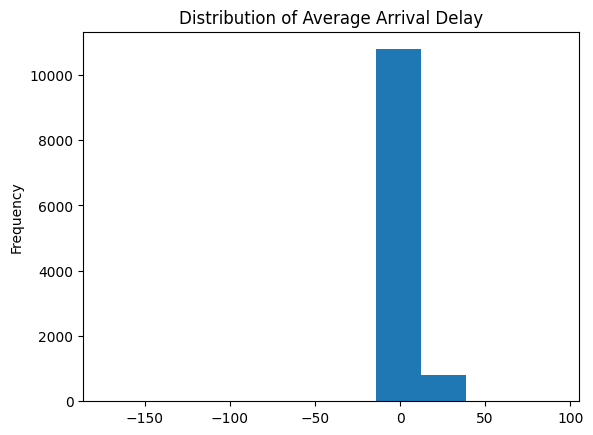

In [39]:
df["Average delay of all trains at arrival"].plot(
    kind="hist",
    bins=10,
    title="Distribution of Average Arrival Delay"
)

This section analyzes the distribution of Average delay of all trains at arrival

<Axes: title={'center': 'Boxplot of Average Arrival Delay'}>

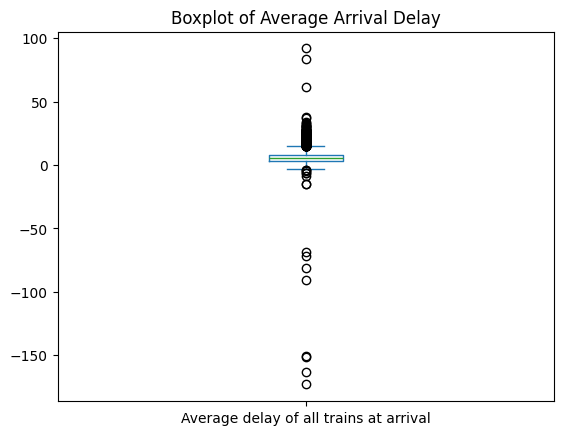

In [40]:
df["Average delay of all trains at arrival"].plot(
    kind="box",
    title="Boxplot of Average Arrival Delay"
)

In [41]:
df.sort_values("Average delay of all trains at arrival", ascending=False).head()

,Date,Service,Departure station,Arrival station,Average journey time,Number of scheduled trains,Number of cancelled trains,Cancellation comments,Number of trains delayed at departure,Average delay of late trains at departure,...,Month,Month name,Quarter,Season,Route,Total trains,Cancellation rate,Departure delay rate,Arrival delay rate,Delay severity
4326,2020-11-01,National,MARSEILLE ST CHARLES,TOURCOING,293.0,3.0,1.0,-,2.0,84.516667,...,11,November,4,Autumn,MARSEILLE ST CHARLES -> TOURCOING,3.0,0.333333,0.666667,0.666667,High
3484,2020-04-01,National,STRASBOURG,PARIS EST,172.0,41.0,38.0,NaN,3.0,10.522222,...,4,April,2,Spring,STRASBOURG -> PARIS EST,41.0,0.926829,0.073171,0.048780,Low
3495,2020-04-01,International,STUTTGART,PARIS EST,106.0,8.0,7.0,NaN,1.0,4.416667,...,4,April,2,Spring,STUTTGART -> PARIS EST,8.0,0.875000,0.125000,0.125000,Medium
3430,2020-04-01,International,PARIS LYON,ZURICH,231.0,24.0,7.0,NaN,4.0,0.216667,...,4,April,2,Spring,PARIS LYON -> ZURICH,24.0,0.291667,0.166667,0.250000,High
891,2018-07-01,National,LYON PART DIEU,RENNES,234.0,86.0,4.0,NaN,79.0,15.840717,...,7,July,3,Summer,LYON PART DIEU -> RENNES,86.0,0.046512,0.918605,0.558140,High


## Average Arrival Delay by Departure Station

In [42]:
departure_arrival_delay = df.groupby("Departure station")["Average delay of all trains at arrival"].mean().sort_values(ascending=False)
departure_arrival_delay

Departure station
nimes                      17.499388
ITALIE                     13.651755
montpellier                13.352691
lyon part dieu             11.908333
MARSEILLE SAINT CHARLES    11.770502
                             ...    
0                           0.697500
Nimes                       0.000000
mulhouse ville              0.000000
nantes                     -0.190991
brest                      -1.131900
Name: Average delay of all trains at arrival, Length: 109, dtype: float64

<Axes: title={'center': 'Top 10 Departure Stations by Average Arrival Delay'}, ylabel='Departure station'>

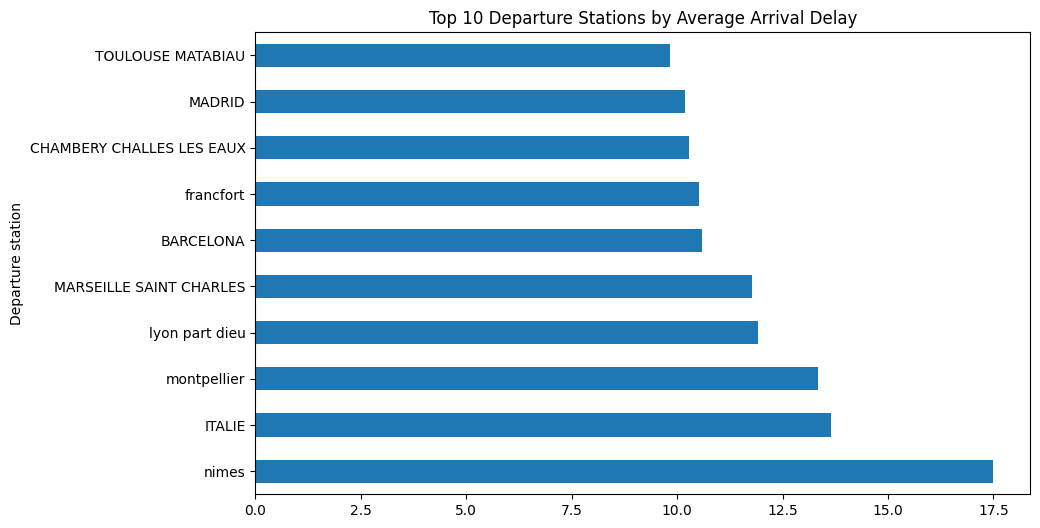

In [43]:
departure_arrival_delay.head(10).plot(
    kind="barh",
    figsize=(10, 6),
    title="Top 10 Departure Stations by Average Arrival Delay"
)

This analysis compares the top 10 departure stations with the highest average arrival delay.